# Diabetes 130-US Hospitals

**Задача:** исследовать госпитализации пациентов с диабетом и возможные сложности прогнозирования повторной госпитализации после выписки.

**Источник:** [UCI Diabetes 130-US Hospitals](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008), файлы `diabetic_data.csv` (данные) и `IDS_mapping.csv` (расшифровка кодов). Для запуска оба файла должны лежать рядом с ноутбуком. Библиотеки: `pandas`, `matplotlib`, `seaborn`.

## 1. Таблица

Размер, типы столбцов, первые строки и сводная статистика. `?` читается как `NaN`, а строка `None` остаётся категорией.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("diabetic_data.csv", na_values=["?"], keep_default_na=False, low_memory=False)
print("Размер:", df.shape)
print("Типы столбцов:", df.dtypes.value_counts().to_dict())
display(df.head())

Размер: (101766, 50)
Типы столбцов: {<StringDtype(storage='python', na_value=nan)>: 37, dtype('int64'): 13}


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [2]:
display(df.describe(include="all").T.round(2))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766.0,NaN,NaN,NaN,54330400.694947,38696359.346534,135.0,23413221.0,45505143.0,87545949.75,189502619.0
race,99493,5,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,3197,9,[75-100),1336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


В таблице 101 766 строк и 50 столбцов: два идентификатора (`encounter_id`, `patient_nbr`), 47 входных признаков и таргет `readmitted`. Целочисленные коды поступления и выписки рассматриваются как категории.

## 2. Таргет

`readmitted` принимает три значения: `NO`, `>30`, `<30`. Исходная постановка по данному столбцу - многоклассовая классификация.

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


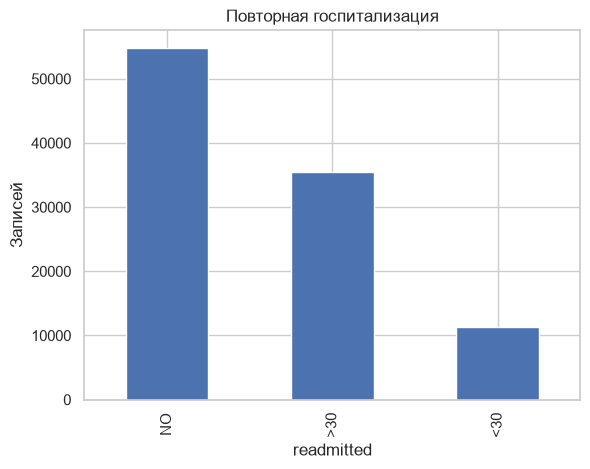

In [3]:
print(df["readmitted"].value_counts())
print((df["readmitted"].value_counts(normalize=True) * 100).round(2))
df["readmitted"].value_counts().reindex(["NO", ">30", "<30"]).plot.bar()
plt.title("Повторная госпитализация")
plt.ylabel("Записей")
plt.show()

`NO` - 54 864 записи (53,91%), `>30` - 35 545 (34,93%), `<30` - 11 357 (11,16%). Если задача будет сформулирована как риск повторной госпитализации в первые 30 дней, потребуется отдельно согласовать бинарное определение таргета.

## 3. Пропуски и специальные обозначения

В исходном CSV пропуски обозначены `?`. Строка `None` в `A1Cresult` и `max_glu_serum` означает отсутствие проведённого анализа и не должна автоматически считаться `NaN`.

In [4]:
missing = pd.DataFrame({"NaN": df.isna().sum(),
                        "NaN, %": (df.isna().mean() * 100).round(2)})
display(missing.loc[missing["NaN"] > 0].sort_values("NaN", ascending=False))
print("NaN среди входных признаков:", int(df.isna().sum().sum()))
print("NaN среди входных ячеек, %:", round(df.isna().sum().sum() / (len(df) * 47) * 100, 2))
print("Строк с NaN:", int(df.isna().any(axis=1).sum()))
print("Полностью заполненных строк:", int(df.notna().all(axis=1).sum()))
print("None в A1Cresult:", (df["A1Cresult"] == "None").sum())
print("None в max_glu_serum:", (df["max_glu_serum"] == "None").sum())
print("Unknown/Invalid в gender:", (df["gender"] == "Unknown/Invalid").sum())

,NaN,"NaN, %"
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


NaN среди входных признаков: 192849
NaN среди входных ячеек, %: 4.03
Строк с NaN: 100723
Полностью заполненных строк: 1043
None в A1Cresult: 84748
None в max_glu_serum: 96420
Unknown/Invalid в gender: 3


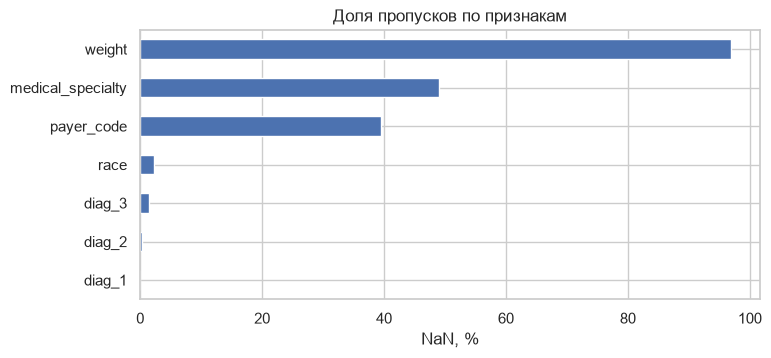

In [5]:
(100 * df.isna().mean()).loc[lambda s: s > 0].sort_values().plot.barh(figsize=(8, 3.5))
plt.title("Доля пропусков по признакам")
plt.xlabel("NaN, %")
plt.show()

Всего 192 849 `NaN` (4,03% ячеек входных признаков) в семи столбцах. Наибольшие доли - у `weight` (96,86%), `medical_specialty` (49,08%) и `payer_code` (39,56%). При этом `None` встречается 84 748 раз в `A1Cresult` и 96 420 раз в `max_glu_serum`. Значения `?` и `None` обозначают разные случаи.

## 4. Идентификаторы и повторы пациентов

Проверяются полные дубликаты, уникальность госпитализаций и количество посещений одного пациента.

In [6]:
visits = df["patient_nbr"].value_counts()
print("Полные дубликаты:", int(df.duplicated().sum()))
print("Повторы encounter_id:", int(df["encounter_id"].duplicated().sum()))
print("Уникальных пациентов:", len(visits))
print("Пациентов с несколькими госпитализациями:", int((visits > 1).sum()))
print("Строк, относящихся к повторяющимся пациентам:", int(df["patient_nbr"].map(visits).gt(1).sum()))
print("Дополнительных госпитализаций сверх одной на пациента:", int((visits - 1).sum()))
print("Максимум госпитализаций одного пациента:", int(visits.max()))

Полные дубликаты: 0
Повторы encounter_id: 0
Уникальных пациентов: 71518
Пациентов с несколькими госпитализациями: 16773
Строк, относящихся к повторяющимся пациентам: 47021
Дополнительных госпитализаций сверх одной на пациента: 30248
Максимум госпитализаций одного пациента: 40


Полных дубликатов нет, `encounter_id` уникален. В 101 766 записях представлены 71 518 пациентов; у 16 773 пациентов более одной госпитализации (47 021 строка). При случайном разбиении госпитализации одного пациента могут оказаться в обучающей и проверочной частях.

## 5. Числовые признаки и потенциальные выбросы

Для количественных показателей проверяются диапазоны, нули, распределения и выбранные IQR-сигналы. Коды категорий в эти проверки не включаются.

In [7]:
quant = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
         "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
display(df[quant].describe().T[["min", "25%", "50%", "75%", "max"]].round(2))
print("Нулей по столбцам:")
print((df[quant] == 0).sum().to_string())
print("Отрицательных измерений:", int(df[quant].lt(0).sum().sum()))

,min,25%,50%,75%,max
time_in_hospital,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,1.0,31.0,44.0,57.0,132.0
num_procedures,0.0,0.0,1.0,2.0,6.0
num_medications,1.0,10.0,15.0,20.0,81.0
number_outpatient,0.0,0.0,0.0,0.0,42.0
number_emergency,0.0,0.0,0.0,0.0,76.0
number_inpatient,0.0,0.0,0.0,1.0,21.0
number_diagnoses,1.0,6.0,8.0,9.0,16.0


Нулей по столбцам:
time_in_hospital          0
num_lab_procedures        0
num_procedures        46652
num_medications           0
number_outpatient     85027
number_emergency      90383
number_inpatient      67630
number_diagnoses          0
Отрицательных измерений: 0


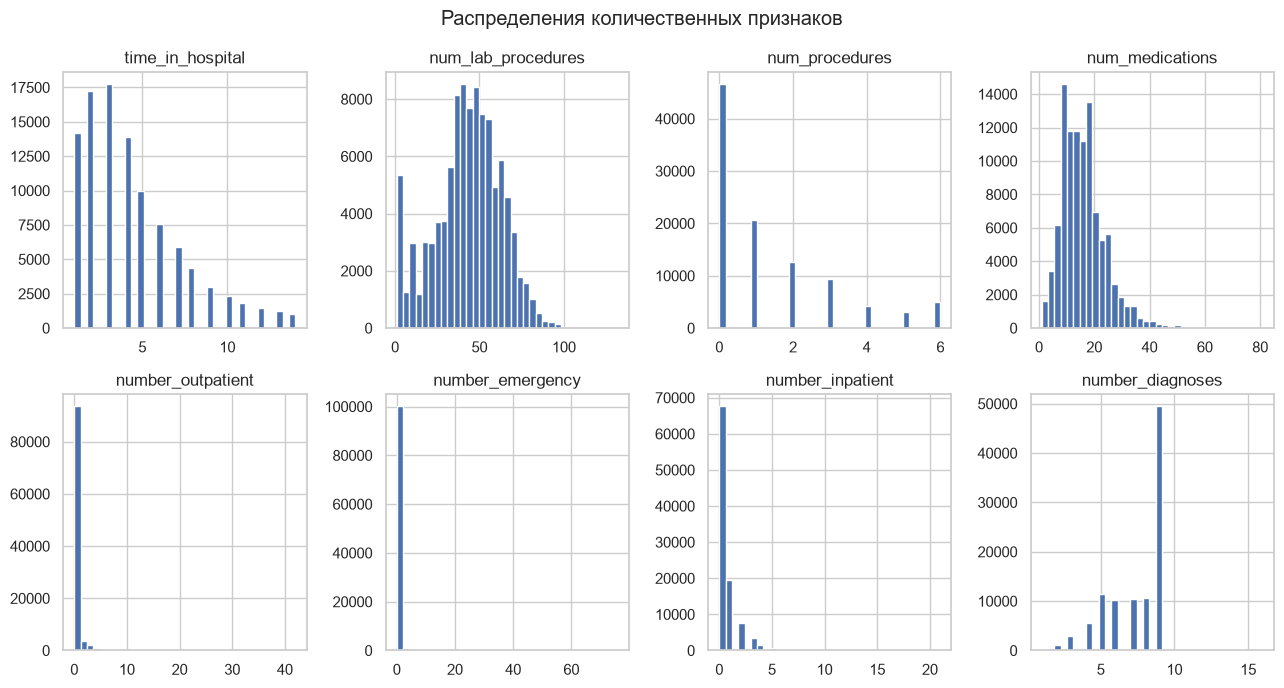

In [8]:
df[quant].hist(bins=35, figsize=(13, 7), layout=(2, 4))
plt.suptitle("Распределения количественных признаков")
plt.tight_layout()
plt.show()

In [9]:
for col in ["time_in_hospital", "num_lab_procedures", "num_medications"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    outliers = df[col].lt(q1 - 1.5 * (q3 - q1)) | df[col].gt(q3 + 1.5 * (q3 - q1))
    print(col, "IQR:", int(outliers.sum()), f"({outliers.mean() * 100:.2f}%)")

time_in_hospital IQR: 2252 (2.21%)
num_lab_procedures IQR: 143 (0.14%)
num_medications IQR: 2557 (2.51%)


Нарушений неотрицательности у восьми количественных признаков нет. `time_in_hospital` принимает значения от 1 до 14 дней. По правилу IQR отмечено 2 252 значения `time_in_hospital` (2,21%), 143 значения `num_lab_procedures` (0,14%) и 2 557 значений `num_medications` (2,51%). Для `number_outpatient`, `number_emergency` и `number_inpatient` характерно большое количество нулей - общий IQR к ним не применяется.

## 6. Категориальные признаки и значения кодов

Сравниваются размер групп и доля ранней повторной госпитализации `<30`. Эта доля используется только для описания данных, не для изменения таргета.

In [10]:
for col in ["age", "gender", "race", "A1Cresult", "max_glu_serum", "change", "diabetesMed"]:
    grouped = df.groupby(col, dropna=False)["readmitted"].agg(
        строк="size", **{"<30, %": lambda s: round(s.eq("<30").mean() * 100, 2)})
    print(col)
    display(grouped.sort_values("строк", ascending=False))

age


,строк,"<30, %"
age,,
[70-80),26068,11.77
[60-70),22483,11.13
[50-60),17256,9.67
[80-90),17197,12.08
[40-50),9685,10.60
[30-40),3775,11.23
[90-100),2793,11.10
[20-30),1657,14.24
[10-20),691,5.79


gender


,строк,"<30, %"
gender,,
Female,54708,11.25
Male,47055,11.06
Unknown/Invalid,3,0.00


race


,строк,"<30, %"
race,,
Caucasian,76099,11.29
AfricanAmerican,19210,11.22
NaN,2273,8.27
Hispanic,2037,10.41
Other,1506,9.63
Asian,641,10.14


... (4 outputs left out)

change


,строк,"<30, %"
change,,
No,54755,10.59
Ch,47011,11.82


diabetesMed


,строк,"<30, %"
diabetesMed,,
Yes,78363,11.63
No,23403,9.60


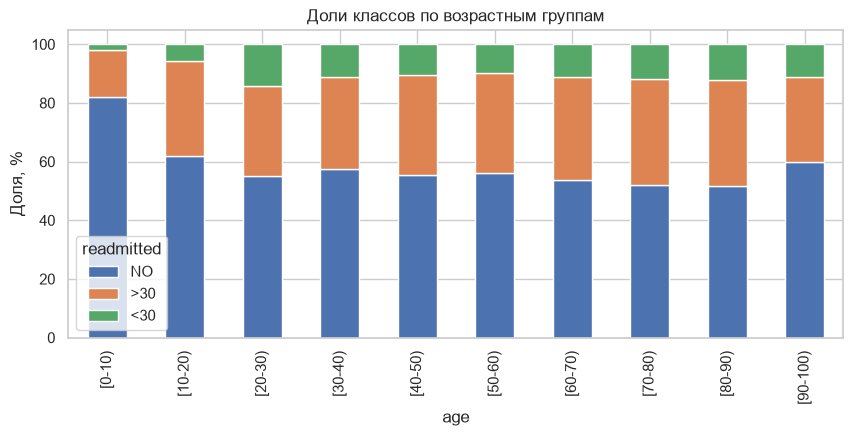

In [11]:
age_order = sorted(df["age"].unique())
(100 * pd.crosstab(df["age"], df["readmitted"], normalize="index")).reindex(age_order)[
    ["NO", ">30", "<30"]].plot.bar(stacked=True, figsize=(10, 4))
plt.title("Доли классов по возрастным группам")
plt.ylabel("Доля, %")
plt.show()

Крупнейшая возрастная группа - `[70-80)` (26 068 записей), доля `<30` в ней составляет 11,77%. У `[80-90)` - 12,08% (17 197 записей). В `gender` есть три строки `Unknown/Invalid`. Для `A1Cresult = None` доля `<30` составляет 11,42% (84 748 записей), для `>8` - 9,87% (8 216 записей). Различия рассчитаны без учёта других признаков.

### Лекарственные признаки

Таблица по всем лекарственным признакам показывает количество записей со значениями, отличными от `No`, и число уникальных категорий.

In [12]:
med_cols = df.loc[:, "metformin":"metformin-pioglitazone"].columns
med_summary = pd.DataFrame({"Категорий": df[med_cols].nunique(),
                            "Не No": df[med_cols].ne("No").sum()})
print("Лекарственных признаков:", len(med_cols))
display(med_summary.sort_values("Не No", ascending=False))

Лекарственных признаков: 23


,Категорий,Не No
insulin,4,54383
metformin,4,19988
glipizide,4,12686
glyburide,4,10650
pioglitazone,4,7328
rosiglitazone,4,6365
glimepiride,4,5191
repaglinide,4,1539
glyburide-metformin,4,706
nateglinide,4,703


Из 23 лекарственных признаков `examide` и `citoglipton` постоянны: во всех строках `No`. Для `insulin` значение, отличное от `No`, встречается 54 383 раза, для `metformin` - 19 988. Малочисленные категории требуют учёта при анализе редких групп.

### Диагнозы и коды поступления/выписки

`diag_1`, `diag_2`, `diag_3` содержат категориальные коды диагнозов. Значения `admission_type_id`, `admission_source_id` и `discharge_disposition_id` расшифровываются через `IDS_mapping.csv`.

In [12]:
print("Количество разных кодов диагнозов:")
print(df[["diag_1", "diag_2", "diag_3"]].nunique().to_string())
for col in ["admission_type_id", "admission_source_id", "discharge_disposition_id"]:
    print(col)
    display(df[col].value_counts().head(10))

Количество разных кодов диагнозов:
diag_1    716
diag_2    748
diag_3    789
admission_type_id


admission_type_id
1    53990
3    18869
2    18480
6     5291
5     4785
8      320
7       21
4       10
Name: count, dtype: int64

admission_source_id


admission_source_id
7     57494
1     29565
17     6781
4      3187
6      2264
2      1104
5       855
3       187
20      161
9       125
Name: count, dtype: int64

discharge_disposition_id


discharge_disposition_id
1     60234
3     13954
6     12902
18     3691
2      2128
22     1993
11     1642
5      1184
25      989
4       815
Name: count, dtype: int64

In [13]:
print("admission_type_id 5/6/8:", int(df["admission_type_id"].isin([5, 6, 8]).sum()))
print("admission_source_id 9/15/17/20/21:", int(df["admission_source_id"].isin([9, 15, 17, 20, 21]).sum()))
print("discharge_disposition_id 18/25/26:", int(df["discharge_disposition_id"].isin([18, 25, 26]).sum()))
print("Разных кодов выписки:", df["discharge_disposition_id"].nunique())

admission_type_id 5/6/8: 10396
admission_source_id 9/15/17/20/21: 7067
discharge_disposition_id 18/25/26: 4680
Разных кодов выписки: 26


У диагнозов высокая кардинальность: 716, 748 и 789 различных кодов. В отображаемых числовыми ID категориях встречаются значения, обозначающие `Not Available`, `NULL`, `Not Mapped` и другие неопределённые состояния. По `IDS_mapping.csv` при поступлении к ним относятся коды 5, 6, 8 - 10 396 строк. Для источника поступления выбранные коды 9, 15, 17, 20, 21 - 7 067 строк. Для выписки 18, 25, 26 - 4 680 строк.

## 7. Связь признаков с таргетом

Сравниваются медианы количественных показателей по трём классам. Отдельно исследуется связь с индикатором `<30`.

In [14]:
display(df.groupby("readmitted")[quant].median().T.reindex(columns=["NO", ">30", "<30"]))
prior = df["number_inpatient"].clip(upper=3)
prior_summary = df.groupby(prior)["readmitted"].agg(
    строк="size", **{"<30, %": lambda s: round(s.eq("<30").mean() * 100, 2)})
prior_summary.index = ["0", "1", "2", "3+"]
print("История госпитализаций:")
display(prior_summary)

readmitted,NO,>30,<30
time_in_hospital,3.0,4.0,4.0
num_lab_procedures,44.0,45.0,45.0
num_procedures,1.0,1.0,1.0
num_medications,14.0,15.0,16.0
number_outpatient,0.0,0.0,0.0
number_emergency,0.0,0.0,0.0
number_inpatient,0.0,0.0,0.0
number_diagnoses,8.0,9.0,9.0


История госпитализаций:


,строк,"<30, %"
0,67630,8.44
1,19521,12.92
2,7566,17.43
3+,7049,25.66


Корреляции с индикатором <30:
number_inpatient      0.165
number_emergency      0.061
number_diagnoses      0.050
time_in_hospital      0.044
num_medications       0.038
num_lab_procedures    0.020
number_outpatient     0.019
num_procedures       -0.012


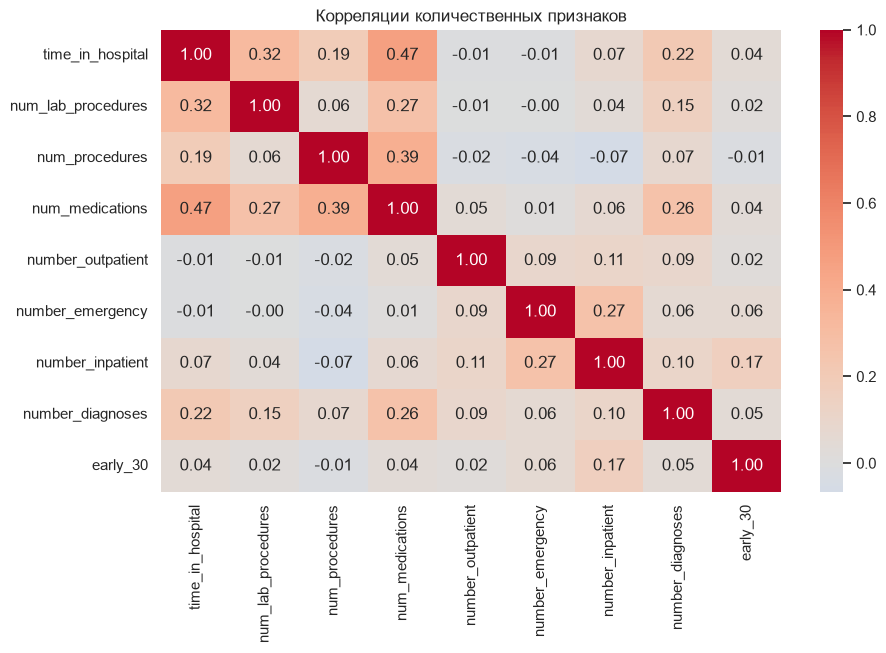

In [15]:
corr = df[quant].assign(early_30=df["readmitted"].eq("<30").astype(int)).corr()
print("Корреляции с индикатором <30:")
print(corr["early_30"].drop("early_30").sort_values(ascending=False).round(3).to_string())
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции количественных признаков")
plt.show()

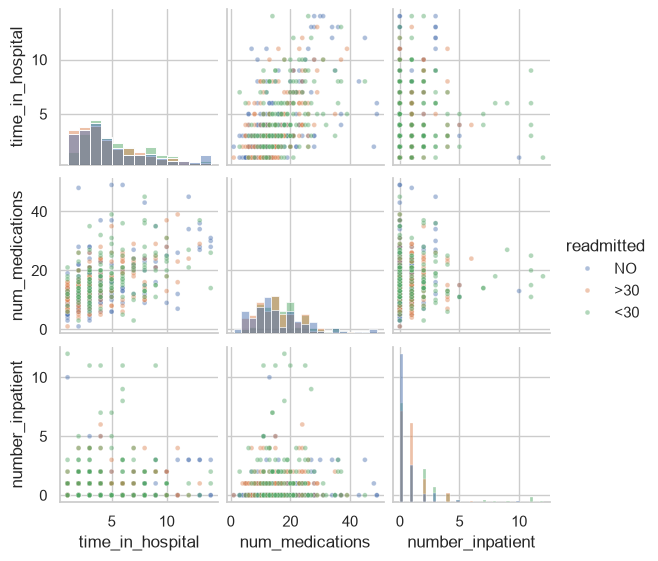

In [16]:
sample = pd.concat([df.loc[df["readmitted"].eq(c)].sample(150, random_state=7)
                    for c in ["NO", ">30", "<30"]])
sns.pairplot(sample, vars=["time_in_hospital", "num_medications", "number_inpatient"],
             hue="readmitted", diag_kind="hist", height=1.9, plot_kws={"alpha": 0.45, "s": 12})
plt.show()

Медиана `num_medications` по классам `NO` / `>30` / `<30` составляет 14 / 15 / 16. Для `number_inpatient = 0` доля `<30` равна 8,44% (67 630 записей), при `1` - 12,92% (19 521), при `2` - 17,43% (7 566), при `3+` - 25,66% (7 049). Линейная корреляция `number_inpatient` с индикатором `<30` составляет около 0,165. Для `pairplot` взято по 150 записей каждого класса.

## 8. Коды выписки и момент прогноза

По расшифровке `IDS_mapping.csv` некоторые коды выписки обозначают смерть или направление в хоспис. Проверяется их распределение по таргету.

In [17]:
disposition = pd.Series("прочее", index=df.index)
disposition.loc[df["discharge_disposition_id"].isin([11, 19, 20, 21])] = "смерть"
disposition.loc[df["discharge_disposition_id"].isin([13, 14])] = "хоспис"
print("Коды смерти:", (disposition == "смерть").sum())
print("Коды хосписа:", (disposition == "хоспис").sum())
print("Хоспис, readmitted не NO:", ((disposition == "хоспис") & df["readmitted"].ne("NO")).sum())
display(pd.crosstab(disposition, df["readmitted"]))

Коды смерти: 1652
Коды хосписа: 771
Хоспис, readmitted не NO: 86


readmitted,<30,>30,NO
row_0,,,
прочее,11314,35502,52527
смерть,0,0,1652
хоспис,43,43,685


Для кодов смерти - 1 652 записи и только `NO`; для хосписа - 771 запись, включая 86 случаев с `readmitted`, отличным от `NO`. Эти значения не меняются. `discharge_disposition_id`, `time_in_hospital`, результаты анализов и сведения о лечении требуют проверки доступности в выбранный момент прогноза. В данных нет отдельного столбца с датой/временем госпитализации или выписки, поэтому строгое временное разбиение по ним не воспроизводится.

## 9. Выводы и эталон для агента

1. **Цель:** `readmitted`, исходы `NO`, `>30`, `<30`. Исходная постановка - многоклассовая классификация.
2. **Постановка:** для задачи повторной госпитализации в первые 30 дней отдельно уточнять необходимость бинарного таргета.
3. **Пропуски:** распознавать `?` как отсутствие значения, отличать от категории `None`.
4. **Идентификаторы:** `encounter_id` не является характеристикой пациента; `patient_nbr` требуется учитывать при разделении данных.
5. **Валидация:** не допускать попадания одного пациента в обучение и проверку. Строгое временное разбиение по исходным полям недоступно.
6. **Категории:** коды диагнозов, поступления и выписки не интерпретировать как непрерывные числовые показатели.
7. **Слабые и редкие признаки:** проверить `weight` с большим числом пропусков и постоянные лекарственные поля.
8. **Риск утечки:** согласовать прогноз при поступлении или выписке и доступность результатов лечения, анализов и кода выписки.
9. **Метрика:** выбирать с учётом дисбаланса, классов и цены пропущенных повторных госпитализаций.